# Flow and volume shift toward veins when total blood pressure increases?

Consider a lumped **two-compartment** systemic circulation:
- **Arterial compartment** with compliance ($C_a$) and unstretched volume ($V_{0,a}$)
- **Venous compartment** with compliance ($C_v$) and unstretched volume ($V_{0,v}$)
- Total blood volume ($V_T$) is conserved: ($V_T = V_a + V_v$).
- Systemic resistance ($R_s$) couples arterial to venous via flow ($Q_s = (P_a - P_v)/R_s$).
- A heart-like pump returns venous blood to arteries; for steady-state analysis we model it as an **external pump** imposing a flow ($Q_{in}$).

**Constitutive law (linearized pressure–volume):**
$$
P_a = \frac{V_a - V_{0,a}}{C_a}, \qquad
P_v = \frac{V_v - V_{0,v}}{C_v}
$$

**Blood Flow**
$$
Q = \frac{\Delta P}{R} 
$$

**Compliance**
$$
C = \frac{\Delta P}{R} 
$$


The relationship between **blood volume** and **vascular compliance** is fundamental in cardiovascular physiology because it determines how the circulatory system accommodates changes in blood volume without large fluctuations in pressure.

### **Key Concepts**

* **Vascular Compliance (C)**  
    Compliance is defined as:
    $$
    C = \frac{\Delta V}{\Delta P}
    $$
    where:

    *   $\Delta V$ = change in blood volume
    *   $\Delta P$ = change in pressure

    High compliance means the vessel can accommodate a large change in volume with a small change in pressure. Low compliance means even small volume changes cause large pressure changes.

* **Blood Volume and Pressure Relationship**
    *   In **high-compliance vessels** (e.g., veins), adding blood volume causes only a slight increase in pressure. This is why veins act as a reservoir for blood.
    *   In **low-compliance vessels** (e.g., arteries), even small increases in blood volume significantly raise pressure, which is critical for maintaining perfusion.

* **Physiological Implications**
    *   **Veins**: \~65% of blood volume is stored here because of their high compliance.
    *   **Arteries**: Low compliance ensures that pressure remains high enough to drive blood flow to tissues.
    *   **Pathology**: Reduced compliance (e.g., arterial stiffness in aging or hypertension) means that the same blood volume leads to higher pressures, increasing cardiac workload.



### Exercise: Stressed vs Unstressed Volume

1. Explain the meaning of unstressed vs stressed volume.
2. Why is $C_v$ ≫ $C_a$ physiologically reasonable?
3. Which compartment stores most stressed volume, and why?
4. What happens to $P_{ms}$ when venous compliance is reduced (i.e. try make a second line in the plot, where $C_{V_{reduced}} = C_V / 2$), if the body has `5L` of total blood volume.
5. How does $V_0$ modify total blood volume at zero pressure?

**Answers**

1. **Unstressed vs stressed volume:**  
  - Unstressed volume ($V_0$): the volume of blood occupying a vascular compartment when transmural pressure is zero — it produces no distending (hydrostatic) pressure.  
  - Stressed volume: the extra volume above $V_0$ ($V − V_0$) that stretches the vessel wall and generates intravascular pressure.  
  - Relation: pressure in a compartment ≈ (stressed volume)/compliance, i.e. $P = (V − V_0)/C$. Stressed volume therefore sets the driving pressure for flow through the circulation; unstressed volume is “stored” without contributing to driving pressure.

2. **Why $C_v$ ≫ $C_a$ is physiologically reasonable:**  
  - Veins have thinner walls, less smooth muscle tone in the passive state, and larger lumens, so they distend much more per unit pressure than arteries.  
  - Arteries are muscular and relatively stiff to maintain high driving pressures.  
  - Numerically, venous compliance is typically an order of magnitude (or more) greater than arterial compliance, which matches physiology and explains why veins act as the major blood reservoir.

3. **Which compartment stores most stressed volume, and why:**  
  - The venous compartment stores most of the total blood volume and, in physiological ranges, most of the stressed volume as well.  
  - Reason: stressed volume in a compartment = compliance × pressure (for a linearized model). Even though venous pressure is lower than arterial pressure, the much larger venous compliance typically makes $C_v \cdot P_v$ larger than $C_a \cdot P_a$. Thus veins both hold most blood and provide the larger share of the pressure-generating (stressed) volume.

4. **What happens to $P_{ms}$ when venous compliance is reduced (i.e. try make a second line in the plot, where $C_{V_{reduced}} = C_V / 2$), if the body has `5L` of total blood volume.**
  - See Figure plot

5. **How does $V_0$ modify total blood volume at zero pressure?**
  - If we have 0 pressure, $V_0 == V_T$, so this will infact be the total blood volume, as there would be no stressed volume

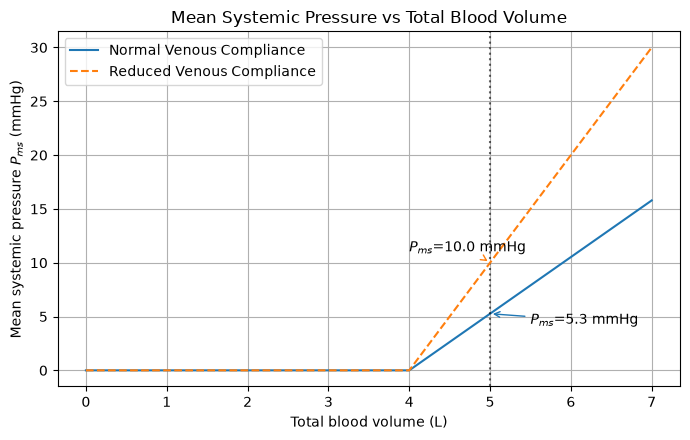

In [29]:
# Vascular function curve: mean systemic pressure vs total blood volume
import matplotlib.pyplot as plt
import numpy as np

# Parameters (mL, mmHg, mL/mmHg) -- consistent with earlier cells
C_a = 0.01  # arterial compliance (L/mmHg)
C_v = 18.0 * C_a  # venous compliance (L/mmHg)
V0 = 4.0  # L total unstressed volume (example)


def calculate_systemic_pressure(V: np.ndarray | float, V0: float, Ca: float, Cv: float):
    # Mean systemic pressure when arterial and venous pressures equilibrate (no flow)
    dV = V - V0
    if isinstance(dV, np.ndarray):
        dV[dV < 0] = 0
    else:
        if dV < 0:
            dV = 0
    pms = dV / (Ca + Cv)
    return pms


# Range of total blood volumes (mL)
V_range = np.linspace(0, 7, 71)

# Baseline P_ms
P_base = calculate_systemic_pressure(V_range, V0, C_a, C_v)

# Plot
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(V_range, P_base, label="Normal Venous Compliance", color="C0")


# Mark vertical line at 5 L and annotate intersections
V_mark = 5.0
P_mark_base = calculate_systemic_pressure(V_mark, V0, C_a, C_v)

ax.axvline(V_mark, color="k", alpha=0.6, linestyle=":")
ax.annotate(
    f"$P_{{ms}}$={P_mark_base:.1f} mmHg",
    xy=(V_mark, P_mark_base),
    xytext=(V_mark+.5 , P_mark_base-1 ),
    arrowprops=dict(arrowstyle="->", color="C0"),
)

''' Answer to the question: What happens to mean systemic pressure when venous compliance is reduced? '''
# Reduced venous compliance scenario (e.g., venoconstriction, fibrosis)
C_v_reduced = C_v * 0.5  # reduce venous compliance by 50%
P_reducedCv = calculate_systemic_pressure(V_range, V0, C_a, C_v_reduced)
ax.plot(
    V_range, P_reducedCv, label="Reduced Venous Compliance", color="C1", linestyle="--"
)
P_mark_reduced = calculate_systemic_pressure(V_mark, V0, C_a, C_v_reduced)
ax.annotate(
    f"$P_{{ms}}$={P_mark_reduced:.1f} mmHg",
    xy=(V_mark, P_mark_reduced),
    xytext=(V_mark-1, P_mark_reduced+1),
    arrowprops=dict(arrowstyle="->", color="C1"),
)


ax.set_xlabel("Total blood volume (L)")
ax.set_ylabel("Mean systemic pressure $P_{ms}$ (mmHg)")
ax.set_title("Mean Systemic Pressure vs Total Blood Volume")
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()